# Shared Nesterov-optimal batch scaling

This experiment fixes

$$
s=0.3,\qquad \beta=4,
\qquad
D\in\{2000,4000,8000,16000,32000,64000,128000\}.
$$

SGD, Polyak momentum, and Nesterov all use the same batch-size scaling,

$$
B\asymp D^{a_{\rm Nes}^\star},
$$

where $a_{\rm Nes}^\star$ is the Nesterov-optimal batch exponent. Hence the
three algorithms also have the same number-of-steps scaling
$K\asymp D^{1-a_{\rm Nes}^\star}$.

The remaining parameters are chosen separately for each algorithm:

- SGD uses its best admissible learning-rate scaling at this oversized batch.
- Polyak rescales $1-\rho$ so that it still attains the standard
  data-optimal rate $D^{-s/(s+1)}$.
- Nesterov uses its own optimal momentum scaling and attains its accelerated
  data-scaling rate.

There is no hyperparameter search. The finite multiplicative constants are
specified explicitly in the configuration cell.

Each configuration runs 100 independent trajectories. For a trajectory with
$K$ optimization steps, define

$$
L_K=\max\{1,\lceil 0.01K\rceil\}.
$$

The reported metric for that trajectory is the mean excess loss over its last
$L_K$ optimization steps:

$$
\overline{\mathcal E}_{K,\mathrm{tail}}
=
\frac{1}{L_K}
\sum_{t=K-L_K+1}^{K}\mathcal E_t.
$$

The experiment then averages this quantity across the 100 independent runs:

$$
\frac1{100}
\sum_{r=1}^{100}
\overline{\mathcal E}_{K,\mathrm{tail}}^{(r)}.
$$

The experiment uses the covariance-surrogate power-law kernel-regression model

$$
g_t=He_t+\xi_t,\qquad
\operatorname{Cov}(\xi_t\mid e_t)
=
\frac{\mathcal E_t+\sigma^2}{B}H.
$$

The final figure displays isolated markers. For each algorithm, a dashed
prediction line with the same color passes through the fourth, middle data
point. The three prediction lines share one black dashed `Prediction` entry
in the legend.


## Shared-batch scaling choices

Write

$$
B\asymp D^a,\qquad
K\asymp D^{1-a},\qquad
1-\rho\asymp D^{-b},\qquad
\eta\asymp D^{-c}.
$$

Because \(s=0.3<1-\frac{1}{2\beta}=\frac{7}{8}\), the low-\(s\)
Nesterov branch applies. Define

$$
x_{\rm Nes}
=
\frac{s\beta}{s\beta+2\beta-1}
=
\frac{6}{41}.
$$

The Nesterov-optimal batch exponent is

$$
a_{\rm shared}
=
a_{\rm Nes}^\star
=
2x_{\rm Nes}
=
\frac{12}{41}.
$$

Therefore, all three algorithms use

$$
B\asymp D^{12/41},
\qquad
K\asymp D^{29/41}.
$$

### SGD at the shared batch size

For SGD,

$$
\mathcal E_D^{\rm SGD}
\asymp
(\eta K)^{-s}+\frac{\eta}{B}.
$$

At the fixed batch exponent \(a=12/41\), the unconstrained balancing choice
would require a growing learning rate. Under the stability restriction
\(\eta\lesssim1\), the best admissible choice is therefore

$$
c_{\rm SGD}=0,
\qquad
\eta_{\rm SGD}\asymp1.
$$

The bias term dominates, giving

$$
p_{\rm SGD,shared}
=
s(1-a_{\rm shared})
=
\frac{87}{410}
\approx0.212.
$$

Thus, SGD no longer attains its data-optimal exponent

$$
\frac{s}{s+1}
=
\frac{3}{13}
\approx0.231.
$$

### Polyak momentum at the shared batch size

Polyak preserves its optimal rate when its effective learning rate obeys

$$
\frac{\eta}{1-\rho}
\asymp
BD^{-s/(s+1)}.
$$

Choose \(\eta_{\rm Pol}\asymp1\). Then

$$
b_{\rm Pol}
=
a_{\rm shared}-\frac{s}{s+1}
=
\frac{12}{41}-\frac{3}{13}
=
\frac{33}{533},
$$

so

$$
1-\rho_{\rm Pol}
\asymp
D^{-33/533}.
$$

This yields

$$
p_{\rm Pol}
=
\frac{s}{s+1}
=
\frac{3}{13}
\approx0.231.
$$

### Nesterov at its optimal batch size

For Nesterov, the theorem prescribes

$$
\frac{\eta_{\rm Nes}}{1-\rho_{\rm Nes}}
\asymp
D^{x_{\rm Nes}}.
$$

Choose \(\eta_{\rm Nes}\asymp1\), so

$$
b_{\rm Nes}
=
x_{\rm Nes}
=
\frac{6}{41},
\qquad
1-\rho_{\rm Nes}
\asymp
D^{-6/41}.
$$

The resulting accelerated exponent is

$$
p_{\rm Nes}
=
\frac{s(2\beta-1)}
{s\beta+2\beta-1}
=
\frac{21}{82}
\approx0.256.
$$

Consequently, at the same Nesterov-optimal batch scaling, the predicted
ordering is

$$
p_{\rm Nes}>p_{\rm Pol}>p_{\rm SGD,shared},
$$

namely,

$$
\frac{21}{82}
>
\frac{3}{13}
>
\frac{87}{410}.
$$

In [ ]:
import time
import zlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# =============================================================================
# Global plotting settings
# =============================================================================

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "sans-serif",
    "axes.titlesize": 16,
    "axes.labelsize": 16,
    "lines.linewidth": 2,
    "lines.markersize": 6,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.figsize": (5, 4),
    "legend.fontsize": 10,
    "legend.handlelength": 1,
})

# =============================================================================
# 1. Configuration
# =============================================================================

BETA = 4.0
S_VALUE = 0.3
SIGMA = 0.1

DIM = 4096
N_RUNS = 100
D_LIST = [2000, 4000, 8000, 16000, 32000, 64000, 128000]
BASE_SEED = 20260725
TAIL_FRACTION = 0.01
EPSILON = 0.05

CURRENT_DIR = Path.cwd()
OUTPUT_DIR = (
    CURRENT_DIR
    if CURRENT_DIR.name == "nag_acc"
    else CURRENT_DIR / "nag_acc"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# =============================================================================
# Shared batch size
#
# The supremal Nesterov-optimal batch exponent is
#
#     a_Nes,max = (2 s beta + 1) / (2 s beta + beta + 1).
#
# All three methods use the same batch exponent
#
#     a_shared = a_Nes,max - EPSILON.
#
# At this fixed batch size, each method uses its own optimal scaling of
# eta and, for momentum methods, 1-rho.
# =============================================================================

BASE_OPTIMAL_EXPONENT = S_VALUE / (S_VALUE + 1.0)

NAG_OPTIMAL_DENOMINATOR = (
    2.0 * S_VALUE * BETA
    + BETA
    + 1.0
)

NAG_MAX_BATCH_EXPONENT = (
    2.0 * S_VALUE * BETA + 1.0
) / NAG_OPTIMAL_DENOMINATOR

SHARED_BATCH_EXPONENT = (
    NAG_MAX_BATCH_EXPONENT - EPSILON
)

if not (0.0 < SHARED_BATCH_EXPONENT < 1.0):
    raise ValueError(
        "EPSILON makes the shared batch exponent invalid."
    )


# -------------------------------------------------------------------------
# SGD at the shared batch exponent
#
# At fixed a, balance
#
#     s(1-a-c)  and  a+c,
#
# subject to c >= 0. For the current shared batch exponent, a exceeds
# s/(s+1), so the best admissible choice is c=0.
# -------------------------------------------------------------------------

SGD_A = SHARED_BATCH_EXPONENT
SGD_B = 0.0
SGD_C = max(
    BASE_OPTIMAL_EXPONENT - SGD_A,
    0.0,
)

P_SGD = min(
    S_VALUE * (1.0 - SGD_A - SGD_C),
    SGD_A + SGD_C,
)


# -------------------------------------------------------------------------
# Polyak momentum at the shared batch exponent
#
# The optimal family satisfies
#
#     a + c - b = s/(s+1).
#
# We choose the largest admissible learning-rate scaling, c=0 whenever
# a >= s/(s+1), and then set b=a-s/(s+1).
# -------------------------------------------------------------------------

HB_A = SHARED_BATCH_EXPONENT
HB_C = max(
    BASE_OPTIMAL_EXPONENT - HB_A,
    0.0,
)
HB_B = HB_A + HB_C - BASE_OPTIMAL_EXPONENT

P_HB = BASE_OPTIMAL_EXPONENT


# -------------------------------------------------------------------------
# Nesterov momentum at the shared batch exponent
#
# On the improving branch c <= b, write x=a+c-b. At fixed a, balancing
# deterministic bias and additive noise gives
#
#     s(1-x) = a + (x-a)/beta,
#
# hence
#
#     x = [s beta - (beta-1)a] / (s beta + 1).
#
# The optimal choice at fixed a uses c=0 and b=a-x.
# -------------------------------------------------------------------------

NAG_A = SHARED_BATCH_EXPONENT

if NAG_A >= BASE_OPTIMAL_EXPONENT:
    NAG_C = 0.0
    NAG_X = (
        S_VALUE * BETA
        - (BETA - 1.0) * NAG_A
    ) / (S_VALUE * BETA + 1.0)
    NAG_B = NAG_A - NAG_X
    P_NAG = S_VALUE * (1.0 - NAG_X)
else:
    # Below the SGD/Polyak critical batch exponent, Nesterov can attain
    # the common rate s/(s+1) without using a growing effective LR.
    NAG_B = 0.0
    NAG_C = BASE_OPTIMAL_EXPONENT - NAG_A
    NAG_X = NAG_A + NAG_C - NAG_B
    P_NAG = BASE_OPTIMAL_EXPONENT

NAG_Y = NAG_A + NAG_B


# =============================================================================
# Finite multiplicative constants
#
# All three algorithms use exactly the same finite batch constant.
# =============================================================================

SHARED_BATCH_CONSTANT = 0.15

SGD_BATCH_CONSTANT = SHARED_BATCH_CONSTANT
HB_BATCH_CONSTANT = SHARED_BATCH_CONSTANT
NAG_BATCH_CONSTANT = SHARED_BATCH_CONSTANT

SGD_ETA_CONSTANT = 0.30

HB_ETA_CONSTANT = 0.10
HB_GAP_CONSTANT = 1.0

NAG_ETA_CONSTANT = 0.10
NAG_GAP_CONSTANT = 2.0


# =============================================================================
# Verify theoretical conditions
# =============================================================================

assert S_VALUE > 0.0
assert BETA > 1.0
assert EPSILON > 0.0

# All algorithms use exactly the same batch scaling.
assert np.isclose(SGD_A, SHARED_BATCH_EXPONENT)
assert np.isclose(HB_A, SHARED_BATCH_EXPONENT)
assert np.isclose(NAG_A, SHARED_BATCH_EXPONENT)
assert np.isclose(SGD_BATCH_CONSTANT, SHARED_BATCH_CONSTANT)
assert np.isclose(HB_BATCH_CONSTANT, SHARED_BATCH_CONSTANT)
assert np.isclose(NAG_BATCH_CONSTANT, SHARED_BATCH_CONSTANT)

assert np.isclose(
    SHARED_BATCH_EXPONENT,
    NAG_MAX_BATCH_EXPONENT - EPSILON,
)

# SGD uses its optimal admissible learning-rate scaling at this fixed batch.
assert SGD_C >= 0.0
assert np.isclose(
    P_SGD,
    min(
        S_VALUE * (1.0 - SGD_A - SGD_C),
        SGD_A + SGD_C,
    ),
)

# Polyak remains in its optimal family.
assert HB_B >= 0.0
assert HB_C >= 0.0
assert np.isclose(
    HB_A + HB_C - HB_B,
    BASE_OPTIMAL_EXPONENT,
)
assert HB_A + HB_B < 1.0
assert HB_C <= 2.0 * HB_B

# Nesterov uses the optimal bias--additive-noise balance at the fixed batch.
assert NAG_B >= 0.0
assert NAG_C >= 0.0
assert NAG_A + NAG_B < 1.0
assert NAG_C <= NAG_B
assert NAG_C <= 2.0 * NAG_B
assert BETA * NAG_A + NAG_C - NAG_B >= 0.0
assert np.isclose(
    S_VALUE * (1.0 - NAG_A - NAG_C + NAG_B),
    NAG_A + (NAG_C - NAG_B) / BETA,
)

# The remaining polynomial multiplicative-noise terms are lower order.
HB_MULTIPLICATIVE_EXPONENT = (
    2.0
    - 1.0 / BETA
    - HB_A
    - HB_B
    + (HB_A + HB_C - HB_B) / BETA
)
NAG_MULTIPLICATIVE_EXPONENT = (
    2.0
    - 1.0 / BETA
    - NAG_A
    - NAG_B
    + (NAG_A + NAG_C - NAG_B) / BETA
)
assert HB_MULTIPLICATIVE_EXPONENT > P_HB
assert NAG_MULTIPLICATIVE_EXPONENT > P_NAG

# Predicted ordering at the shared batch exponent for the current setup.
assert P_NAG > P_HB > P_SGD


# =============================================================================
# Plot labels and prediction exponents
# =============================================================================

GROUP_ORDER = ["sgd", "hb", "nag"]

GROUP_LABELS = {
    "sgd": "SGD",
    "hb": "Polyak",
    "nag": "Nesterov",
}

THEORY_EXPONENTS = {
    "sgd": P_SGD,
    "hb": P_HB,
    "nag": P_NAG,
}

# Use the fourth experimental point, the middle of the seven D values,
# as the anchor of every prediction line.
THEORY_ANCHOR_INDEX = 3


# =============================================================================
# Print configuration
# =============================================================================

print(f"beta={BETA:g}, s={S_VALUE:g}, sigma={SIGMA:g}")
print(f"dim={DIM}, nruns={N_RUNS}")
print(f"epsilon={EPSILON:g}")
print(f"tail fraction={TAIL_FRACTION:.2%}")
print(f"D values={D_LIST}")
print(f"output directory={OUTPUT_DIR.resolve()}")
print()

print(
    "Nesterov maximal batch exponent: "
    f"a_max={NAG_MAX_BATCH_EXPONENT:.9f}"
)
print(
    "Shared batch: "
    f"a={SHARED_BATCH_EXPONENT:.9f}, "
    f"B0={SHARED_BATCH_CONSTANT:g}"
)
print()

print(
    "SGD: "
    f"a={SGD_A:.9f}, "
    f"c={SGD_C:.9f}, "
    f"eta0={SGD_ETA_CONSTANT:g}, "
    f"p={P_SGD:.9f}"
)
print(
    "Polyak: "
    f"a={HB_A:.9f}, "
    f"b={HB_B:.9f}, "
    f"c={HB_C:.9f}, "
    f"eta0={HB_ETA_CONSTANT:g}, "
    f"gap0={HB_GAP_CONSTANT:g}, "
    f"p={P_HB:.9f}"
)
print(
    "Nesterov: "
    f"a={NAG_A:.9f}, "
    f"b={NAG_B:.9f}, "
    f"c={NAG_C:.9f}, "
    f"eta0={NAG_ETA_CONSTANT:g}, "
    f"gap0={NAG_GAP_CONSTANT:g}, "
    f"p={P_NAG:.9f}"
)


beta=4, s=0.3, sigma=0.1
dim=4096, nruns=100
epsilon=0.05
tail fraction=1.00%
D values=[2000, 4000, 8000, 16000, 32000, 64000, 128000]
output directory=/home/jnwang/momentum/paper/nag_shared_nesterov_batch_corrected

Nesterov maximal batch exponent: a_max=0.459459459
Shared batch: a=0.409459459, B0=0.15

SGD: a=0.409459459, c=0.000000000, eta0=0.3, p=0.177162162
Polyak: a=0.409459459, b=0.178690229, c=0.000000000, eta0=0.1, gap0=1, p=0.230769231
Nesterov: a=0.409459459, b=0.422358722, c=0.000000000, eta0=0.1, gap0=2, p=0.303869779


In [2]:
# =============================================================================
# 2. Power-law kernel-regression problem
# =============================================================================

def build_problem(
    dim=DIM,
    beta=BETA,
    s=S_VALUE,
    dtype=np.float32,
):
    """
    Spectrum:
        lambda_j = j^{-beta}

    Source condition:
        lambda_j * theta_star_j^2 = j^{-1-beta*s}

    Hence:
        theta_star_j^2 = j^{-1-beta*(s-1)}.
    """
    if dim < 1:
        raise ValueError("DIM must be positive.")
    if beta <= 1:
        raise ValueError("BETA must be greater than 1.")
    if s <= 0:
        raise ValueError("S_VALUE must be positive.")

    j = np.arange(1, dim + 1, dtype=np.float64)
    lam = j ** (-beta)
    theta_squared = j ** (
        -(1.0 + beta * (s - 1.0))
    )
    theta_star = np.sqrt(theta_squared)

    return (
        lam.astype(dtype),
        theta_star.astype(dtype),
    )


def excess_loss_batch(delta, lam):
    """Return one excess loss for every row of delta."""
    return 0.5 * np.sum(
        lam[None, :] * delta * delta,
        axis=1,
        dtype=np.float64,
    )


def excess_loss_single(delta, lam):
    return float(
        0.5 * np.sum(
            lam * delta * delta,
            dtype=np.float64,
        )
    )


LAM, THETA_STAR = build_problem()

print(f"lambda_1={LAM[0]:.6e}")
print(f"lambda_DIM={LAM[-1]:.6e}")
print(
    "initial excess loss="
    f"{excess_loss_single(-THETA_STAR, LAM):.6e}"
)

lambda_1=1.000000e+00
lambda_DIM=3.552714e-15
initial excess loss=7.452524e-01


## Iterations being simulated

Let $e_t=\theta_t-\theta^\ast$.

For SGD and Polyak momentum, the stochastic gradient is

$$
g_t=He_t+\xi_t,\qquad
\xi_t\mid e_t
\sim
\mathcal N\left(
0,\frac{\mathcal E(e_t)+\sigma^2}{B}H
\right).
$$

The updates are

$$
e_{t+1}^{\rm SGD}=e_t-\eta g_t,
$$

$$
e_{t+1}^{\rm HB}
=
e_t-\eta g_t+\rho(e_t-e_{t-1}).
$$

For Nesterov, first form the look-ahead error

$$
\widetilde e_t
=
e_t+\rho(e_t-e_{t-1}).
$$

The gradient and noise covariance are evaluated at $\widetilde e_t$:

$$
g_t^{\rm NAG}
=
H\widetilde e_t+\xi_t^{\rm NAG},
$$

$$
\xi_t^{\rm NAG}\mid\widetilde e_t
\sim
\mathcal N\left(
0,
\frac{\mathcal E(\widetilde e_t)+\sigma^2}{B}H
\right),
$$

and

$$
e_{t+1}^{\rm NAG}
=
\widetilde e_t-\eta g_t^{\rm NAG}.
$$

In [3]:
# =============================================================================
# 3. Vectorized SGD / Heavy-Ball / Nesterov simulator
# =============================================================================

def stable_seed(*items):
    text = "|".join(str(item) for item in items)
    return (
        BASE_SEED
        + zlib.crc32(text.encode("utf-8"))
    ) % (2**32 - 1)


def tail_length(num_steps, tail_fraction=TAIL_FRACTION):
    """
    Number of optimization steps included in the tail average.

    For example:
        K=387 -> ceil(3.87)=4 tail steps.
    """
    if num_steps < 1:
        raise ValueError("num_steps must be positive.")
    if not (0.0 < tail_fraction <= 1.0):
        raise ValueError(
            "tail_fraction must lie in (0,1]."
        )

    return max(
        1,
        int(np.ceil(tail_fraction * num_steps)),
    )


def run_optimizer(
    algo,
    batch_size,
    num_steps,
    eta,
    rho,
    lam=LAM,
    theta_star=THETA_STAR,
    sigma=SIGMA,
    n_runs=N_RUNS,
    seed=0,
    tail_fraction=TAIL_FRACTION,
):
    """
    Run N_RUNS independent trajectories and return one metric per run.

    The returned metric is the average excess loss over the final
    ceil(tail_fraction * num_steps) optimization steps.

    Losses are measured after each parameter update. Therefore, for
    optimization steps t=1,...,K, the tail includes

        t = K-L+1, ..., K,

    where L=ceil(tail_fraction*K), with a minimum of one step.

    This simulates the Gaussian covariance surrogate, not explicit
    mini-batch samples.
    """
    if algo not in {"sgd", "hb", "nag"}:
        raise ValueError(f"Unknown algorithm: {algo}.")
    if batch_size < 1:
        raise ValueError("batch_size must be positive.")
    if num_steps < 1:
        raise ValueError("num_steps must be positive.")
    if n_runs < 1:
        raise ValueError("n_runs must be positive.")
    if not (0.0 < eta < 1.0):
        raise ValueError(f"eta must lie in (0,1), got {eta}.")
    if not (0.0 <= rho < 1.0):
        raise ValueError(f"rho must lie in [0,1), got {rho}.")

    rng = np.random.default_rng(seed)
    runs = int(n_runs)
    dim = lam.size

    delta = np.broadcast_to(
        -theta_star,
        (runs, dim),
    ).copy()
    delta_previous = delta.copy()

    lam_row = lam[None, :]
    sqrt_lam_row = np.sqrt(lam).astype(
        np.float32
    )[None, :]

    num_tail_steps = tail_length(
        num_steps,
        tail_fraction,
    )
    first_tail_step = (
        num_steps - num_tail_steps + 1
    )

    # Accumulate one loss sum for every independent trajectory.
    tail_loss_sum = np.zeros(
        runs,
        dtype=np.float64,
    )

    for step in range(1, num_steps + 1):
        if algo == "nag":
            evaluation_delta = (
                delta
                + rho * (delta - delta_previous)
            )
        else:
            evaluation_delta = delta

        evaluation_loss = excess_loss_batch(
            evaluation_delta,
            lam,
        )

        gaussian = rng.standard_normal(
            size=(runs, dim)
        ).astype(
            np.float32,
            copy=False,
        )

        noise_scale = np.sqrt(
            (evaluation_loss + sigma**2)
            / batch_size
        ).astype(np.float32)

        noise = (
            noise_scale[:, None]
            * sqrt_lam_row
            * gaussian
        )
        gradient = (
            lam_row * evaluation_delta
            + noise
        )

        if algo == "sgd":
            next_delta = delta - eta * gradient
        elif algo == "hb":
            next_delta = (
                delta
                - eta * gradient
                + rho * (delta - delta_previous)
            )
        else:
            next_delta = (
                evaluation_delta
                - eta * gradient
            )

        delta_previous, delta = (
            delta,
            next_delta.astype(
                np.float32,
                copy=False,
            ),
        )

        # The metric averages losses after the final 1% of updates.
        if step >= first_tail_step:
            tail_loss_sum += excess_loss_batch(
                delta,
                lam,
            )

    tail_mean_losses = (
        tail_loss_sum / num_tail_steps
    )

    if np.any(~np.isfinite(tail_mean_losses)):
        raise FloatingPointError(
            "Non-finite tail-average loss for "
            f"algo={algo}, B={batch_size}, "
            f"K={num_steps}, eta={eta}, rho={rho}."
        )

    return tail_mean_losses

In [4]:
# =============================================================================
# 4. Finite-D schedules with a shared Nesterov-optimal batch
# =============================================================================

def make_base_schedule(
    D,
    batch_exponent,
    batch_constant,
):
    if D < 1:
        raise ValueError("D must be positive.")

    batch_size = max(
        1,
        int(round(
            batch_constant
            * D ** batch_exponent
        )),
    )

    num_steps = max(
        1,
        int(D // batch_size),
    )

    used_budget = batch_size * num_steps

    return {
        "D": int(D),
        "B": int(batch_size),
        "K": int(num_steps),
        "used_budget": int(used_budget),
        "used_fraction": float(
            used_budget / D
        ),
        "tail_fraction": float(
            TAIL_FRACTION
        ),
        "tail_steps": int(
            tail_length(num_steps)
        ),
        "a": float(batch_exponent),
        "batch_constant": float(
            batch_constant
        ),
    }

def make_sgd_schedule(D):
    schedule = make_base_schedule(
        D,
        SGD_A,
        SGD_BATCH_CONSTANT,
    )

    schedule.update(
        {
            "group": "sgd",
            "algorithm": "sgd",
            "eta": float(
                SGD_ETA_CONSTANT
                * D ** (-SGD_C)
            ),
            "rho": 0.0,
            "one_minus_rho": 1.0,
            "b": float(SGD_B),
            "c": float(SGD_C),
            "p_theory": float(P_SGD),
        }
    )

    return schedule


def make_momentum_schedule(
    D,
    *,
    group,
    batch_exponent,
    batch_constant,
    gap_exponent,
    eta_exponent,
    eta_constant,
    gap_constant,
    theory_exponent,
):
    schedule = make_base_schedule(
        D,
        batch_exponent,
        batch_constant,
    )

    eta = float(
        eta_constant
        * D ** (-eta_exponent)
    )

    one_minus_rho = min(
        1.0,
        gap_constant
        * D ** (-gap_exponent),
    )

    rho = 1.0 - one_minus_rho

    schedule.update(
        {
            "group": group,
            "algorithm": group,
            "eta": eta,
            "rho": float(rho),
            "one_minus_rho": float(
                one_minus_rho
            ),
            "b": float(gap_exponent),
            "c": float(eta_exponent),
            "K_times_gap": float(
                schedule["K"]
                * one_minus_rho
            ),
            "eta_over_gap_squared": float(
                eta / one_minus_rho**2
            ),
            "p_theory": float(
                theory_exponent
            ),
        }
    )

    return schedule


def make_hb_schedule(D):
    return make_momentum_schedule(
        D,
        group="hb",
        batch_exponent=HB_A,
        batch_constant=HB_BATCH_CONSTANT,
        gap_exponent=HB_B,
        eta_exponent=HB_C,
        eta_constant=HB_ETA_CONSTANT,
        gap_constant=HB_GAP_CONSTANT,
        theory_exponent=P_HB,
    )


def make_nag_schedule(D):
    return make_momentum_schedule(
        D,
        group="nag",
        batch_exponent=NAG_A,
        batch_constant=NAG_BATCH_CONSTANT,
        gap_exponent=NAG_B,
        eta_exponent=NAG_C,
        eta_constant=NAG_ETA_CONSTANT,
        gap_constant=NAG_GAP_CONSTANT,
        theory_exponent=P_NAG,
    )


SCHEDULE_FUNCTIONS = {
    "sgd": make_sgd_schedule,
    "hb": make_hb_schedule,
    "nag": make_nag_schedule,
}

SCHEDULE_PREVIEW = pd.concat(
    [
        pd.DataFrame(
            [
                SCHEDULE_FUNCTIONS[group](D)
                for D in D_LIST
            ]
        )
        for group in GROUP_ORDER
    ],
    ignore_index=True,
)

display(SCHEDULE_PREVIEW)

,D,B,K,used_budget,used_fraction,tail_fraction,tail_steps,a,batch_constant,group,algorithm,eta,rho,one_minus_rho,b,c,p_theory,K_times_gap,eta_over_gap_squared
0,2000,3,666,1998,0.999000,0.01,7,0.409459,0.15,sgd,sgd,0.3,0.000000,1.000000,0.000000,0.0,0.177162,NaN,NaN
1,4000,4,1000,4000,1.000000,0.01,10,0.409459,0.15,sgd,sgd,0.3,0.000000,1.000000,0.000000,0.0,0.177162,NaN,NaN
2,8000,6,1333,7998,0.999750,0.01,14,0.409459,0.15,sgd,sgd,0.3,0.000000,1.000000,0.000000,0.0,0.177162,NaN,NaN
3,16000,8,2000,16000,1.000000,0.01,20,0.409459,0.15,sgd,sgd,0.3,0.000000,1.000000,0.000000,0.0,0.177162,NaN,NaN
4,32000,10,3200,32000,1.000000,0.01,32,0.409459,0.15,sgd,sgd,0.3,0.000000,1.000000,0.000000,0.0,0.177162,NaN,NaN
5,64000,14,4571,63994,0.999906,0.01,46,0.409459,0.15,sgd,sgd,0.3,0.000000,1.000000,0.000000,0.0,0.177162,NaN,NaN
6,128000,19,6736,127984,0.999875,0.01,68,0.409459,0.15,sgd,sgd,0.3,0.000000,1.000000,0.000000,0.0,0.177162,NaN,NaN
7,2000,3,666,1998,0.999000,0.01,7,0.409459,0.15,hb,hb,0.1,0.742879,0.257121,0.178690,0.0,0.230769,171.242841,1.512598
8,4000,4,1000,4000,1.000000,0.01,10,0.409459,0.15,hb,hb,0.1,0.772832,0.227168,0.178690,0.0,0.230769,227.167959,1.937786
9,8000,6,1333,7998,0.999750,0.01,14,0.409459,0.15,hb,hb,0.1,0.799296,0.200704,0.178690,0.0,0.230769,267.538389,2.482493


In [5]:
# =============================================================================
# 5. Run all three shared-batch configurations
#
# There is no hyperparameter search.
#
# For each algorithm and each D:
#   1. run N_RUNS independent trajectories;
#   2. for each trajectory, average its losses over the final 1% of steps;
#   3. average those N_RUNS trajectory-level tail means.
# =============================================================================

RESULTS = {
    group: []
    for group in GROUP_ORDER
}

SCHEDULES = {
    group: []
    for group in GROUP_ORDER
}

runtime_rows = []

for group in GROUP_ORDER:
    schedule_function = SCHEDULE_FUNCTIONS[group]

    for D in D_LIST:
        schedule = schedule_function(D)
        start_time = time.time()

        tail_mean_losses = run_optimizer(
            algo=group,
            batch_size=schedule["B"],
            num_steps=schedule["K"],
            eta=schedule["eta"],
            rho=schedule["rho"],
            n_runs=N_RUNS,
            seed=stable_seed(
                "corrected_shared_nesterov_batch_tail_1pct",
                group,
                D,
            ),
            tail_fraction=TAIL_FRACTION,
        )

        elapsed = time.time() - start_time
        mean_tail_loss = float(
            np.mean(tail_mean_losses)
        )

        RESULTS[group].append(
            tail_mean_losses
        )
        SCHEDULES[group].append(schedule)

        runtime_rows.append(
            {
                "group": group,
                "D": int(D),
                "tail steps": schedule["tail_steps"],
                "elapsed seconds": elapsed,
            }
        )

        print(
            f"{group.upper():3s}: "
            f"D={D:6d} | "
            f"B={schedule['B']:4d} | "
            f"K={schedule['K']:4d} | "
            f"tail={schedule['tail_steps']:3d} | "
            f"eta={schedule['eta']:.6f} | "
            f"rho={schedule['rho']:.6f} | "
            f"mean last-1%-steps loss={mean_tail_loss:.6e} | "
            f"{elapsed:.2f}s"
        )


RUNTIME_TABLE = pd.DataFrame(runtime_rows)
display(RUNTIME_TABLE)


SGD: D=  2000 | B=   3 | K= 666 | tail=  7 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=6.464436e-02 | 5.17s
SGD: D=  4000 | B=   4 | K=1000 | tail= 10 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=5.665320e-02 | 7.79s
SGD: D=  8000 | B=   6 | K=1333 | tail= 14 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=5.130149e-02 | 10.38s
SGD: D= 16000 | B=   8 | K=2000 | tail= 20 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=4.524733e-02 | 15.56s
SGD: D= 32000 | B=  10 | K=3200 | tail= 32 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=3.919291e-02 | 24.89s
SGD: D= 64000 | B=  14 | K=4571 | tail= 46 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=3.511475e-02 | 35.49s
SGD: D=128000 | B=  19 | K=6736 | tail= 68 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=3.118346e-02 | 52.27s
HB : D=  2000 | B=   3 | K= 666 | tail=  7 | eta=0.100000 | rho=0.742879 | mean last-1%-steps loss=6.006202e-02 | 5.43s
HB : D=  4000 | B=   4 | K=1000 | t

,group,D,tail steps,elapsed seconds
0,sgd,2000,7,5.167236
1,sgd,4000,10,7.793252
2,sgd,8000,14,10.376783
3,sgd,16000,20,15.564129
4,sgd,32000,32,24.888958
5,sgd,64000,46,35.493177
6,sgd,128000,68,52.272462
7,hb,2000,7,5.433202
8,hb,4000,10,8.177685
9,hb,8000,14,10.950489


In [6]:
# =============================================================================
# 6. Mean last-1%-steps losses and measured log-log slopes
# =============================================================================

def fit_exponent(D_values, mean_losses):
    D_values = np.asarray(
        D_values,
        dtype=np.float64,
    )
    mean_losses = np.asarray(
        mean_losses,
        dtype=np.float64,
    )

    if np.any(~np.isfinite(mean_losses)):
        raise ValueError(
            "Mean losses must be finite."
        )
    if np.any(mean_losses <= 0):
        raise ValueError(
            "Mean losses must be positive."
        )

    slope, intercept = np.polyfit(
        np.log(D_values),
        np.log(mean_losses),
        deg=1,
    )

    # If loss ~ D^{-p}, then log(loss) = const - p log(D).
    return -float(slope), float(intercept)


MEAN_CURVES = {}
THEORY_REFERENCE_CURVES = {}

summary_rows = []
result_rows = []
theory_rows = []

D_ARRAY = np.asarray(
    D_LIST,
    dtype=np.float64,
)

for group in GROUP_ORDER:
    mean_losses = np.asarray(
        [
            float(np.mean(tail_mean_losses))
            for tail_mean_losses in RESULTS[group]
        ],
        dtype=np.float64,
    )
    MEAN_CURVES[group] = mean_losses

    measured_exponent, intercept = fit_exponent(
        D_LIST,
        mean_losses,
    )
    theory_exponent = THEORY_EXPONENTS[group]

    # Anchor the theoretical line at the fourth, middle measured point.
    anchor_index = THEORY_ANCHOR_INDEX
    theory_reference = (
        mean_losses[anchor_index]
        * (D_ARRAY / D_ARRAY[anchor_index]) ** (
            -theory_exponent
        )
    )
    THEORY_REFERENCE_CURVES[group] = theory_reference

    summary_rows.append(
        {
            "group": group,
            "label": GROUP_LABELS[group],
            "theory exponent": theory_exponent,
            "measured exponent": measured_exponent,
            "log-fit intercept": intercept,
            "metric": "mean loss over final 1% of steps",
        }
    )

    for D, tail_mean_losses, schedule in zip(
        D_LIST,
        RESULTS[group],
        SCHEDULES[group],
    ):
        result_rows.append(
            {
                "group": group,
                "label": GROUP_LABELS[group],
                "algorithm": schedule["algorithm"],
                "D": int(D),
                "B": schedule["B"],
                "K": schedule["K"],
                "tail steps": schedule["tail_steps"],
                "eta": schedule["eta"],
                "rho": schedule["rho"],
                "mean last-1%-steps loss": float(
                    np.mean(tail_mean_losses)
                ),
                "theory exponent": theory_exponent,
            }
        )

    for D, predicted_loss in zip(
        D_LIST,
        theory_reference,
    ):
        theory_rows.append(
            {
                "group": group,
                "D": int(D),
                "theory reference loss": float(
                    predicted_loss
                ),
                "theory exponent": theory_exponent,
            }
        )


SLOPE_SUMMARY = pd.DataFrame(summary_rows)
RESULT_TABLE = pd.DataFrame(result_rows)
THEORY_REFERENCE_TABLE = pd.DataFrame(theory_rows)

SCHEDULE_TABLE = pd.concat(
    [
        pd.DataFrame(SCHEDULES[group])
        for group in GROUP_ORDER
    ],
    ignore_index=True,
)

print("Mean losses over the final 1% of steps:")
display(RESULT_TABLE)

print("Measured and predicted exponents:")
display(SLOPE_SUMMARY)

print("Optimal schedules:")
display(SCHEDULE_TABLE)

print("Theoretical reference curves:")
display(THEORY_REFERENCE_TABLE)

Mean losses over the final 1% of steps:


,group,label,algorithm,D,B,K,tail steps,eta,rho,mean last-1%-steps loss,theory exponent
0,sgd,SGD,sgd,2000,3,666,7,0.3,0.000000,0.064644,0.177162
1,sgd,SGD,sgd,4000,4,1000,10,0.3,0.000000,0.056653,0.177162
2,sgd,SGD,sgd,8000,6,1333,14,0.3,0.000000,0.051301,0.177162
3,sgd,SGD,sgd,16000,8,2000,20,0.3,0.000000,0.045247,0.177162
4,sgd,SGD,sgd,32000,10,3200,32,0.3,0.000000,0.039193,0.177162
5,sgd,SGD,sgd,64000,14,4571,46,0.3,0.000000,0.035115,0.177162
6,sgd,SGD,sgd,128000,19,6736,68,0.3,0.000000,0.031183,0.177162
7,hb,Polyak,hb,2000,3,666,7,0.1,0.742879,0.060062,0.230769
8,hb,Polyak,hb,4000,4,1000,10,0.1,0.772832,0.051154,0.230769
9,hb,Polyak,hb,8000,6,1333,14,0.1,0.799296,0.044675,0.230769


Measured and predicted exponents:


,group,label,theory exponent,measured exponent,log-fit intercept,metric
0,sgd,SGD,0.177162,0.175850,-1.402222,mean loss over final 1% of steps
1,hb,Polyak,0.230769,0.229035,-1.065778,mean loss over final 1% of steps
2,nag,Nesterov,0.303870,0.306155,-0.798306,mean loss over final 1% of steps


Optimal schedules:


,D,B,K,used_budget,used_fraction,tail_fraction,tail_steps,a,batch_constant,group,algorithm,eta,rho,one_minus_rho,b,c,p_theory,K_times_gap,eta_over_gap_squared
0,2000,3,666,1998,0.999000,0.01,7,0.409459,0.15,sgd,sgd,0.3,0.000000,1.000000,0.000000,0.0,0.177162,NaN,NaN
1,4000,4,1000,4000,1.000000,0.01,10,0.409459,0.15,sgd,sgd,0.3,0.000000,1.000000,0.000000,0.0,0.177162,NaN,NaN
2,8000,6,1333,7998,0.999750,0.01,14,0.409459,0.15,sgd,sgd,0.3,0.000000,1.000000,0.000000,0.0,0.177162,NaN,NaN
3,16000,8,2000,16000,1.000000,0.01,20,0.409459,0.15,sgd,sgd,0.3,0.000000,1.000000,0.000000,0.0,0.177162,NaN,NaN
4,32000,10,3200,32000,1.000000,0.01,32,0.409459,0.15,sgd,sgd,0.3,0.000000,1.000000,0.000000,0.0,0.177162,NaN,NaN
5,64000,14,4571,63994,0.999906,0.01,46,0.409459,0.15,sgd,sgd,0.3,0.000000,1.000000,0.000000,0.0,0.177162,NaN,NaN
6,128000,19,6736,127984,0.999875,0.01,68,0.409459,0.15,sgd,sgd,0.3,0.000000,1.000000,0.000000,0.0,0.177162,NaN,NaN
7,2000,3,666,1998,0.999000,0.01,7,0.409459,0.15,hb,hb,0.1,0.742879,0.257121,0.178690,0.0,0.230769,171.242841,1.512598
8,4000,4,1000,4000,1.000000,0.01,10,0.409459,0.15,hb,hb,0.1,0.772832,0.227168,0.178690,0.0,0.230769,227.167959,1.937786
9,8000,6,1333,7998,0.999750,0.01,14,0.409459,0.15,hb,hb,0.1,0.799296,0.200704,0.178690,0.0,0.230769,267.538389,2.482493


Theoretical reference curves:


,group,D,theory reference loss,theory exponent
0,sgd,2000,0.065401,0.177162
1,sgd,4000,0.057844,0.177162
2,sgd,8000,0.051159,0.177162
3,sgd,16000,0.045247,0.177162
4,sgd,32000,0.040019,0.177162
5,sgd,64000,0.035394,0.177162
6,sgd,128000,0.031304,0.177162
7,hb,2000,0.061245,0.230769
8,hb,4000,0.052192,0.230769
9,hb,8000,0.044477,0.230769


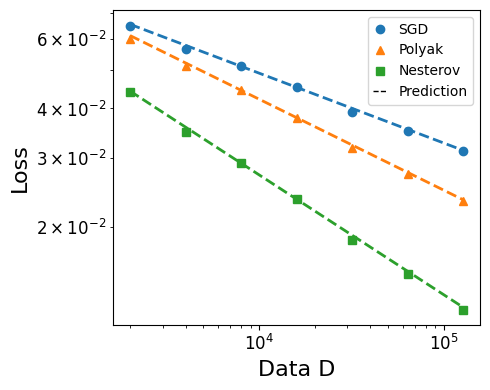

In [7]:
# =============================================================================
# 7. Plot experimental points and prediction lines
# =============================================================================

from matplotlib.lines import Line2D

MARKERS = {
    "sgd": "o",
    "hb": "^",
    "nag": "s",
}

POINT_LABELS = {
    "sgd": "SGD",
    "hb": "Polyak",
    "nag": "Nesterov",
}

D_ARRAY = np.asarray(D_LIST, dtype=np.float64)

if not 0 <= THEORY_ANCHOR_INDEX < len(D_ARRAY):
    raise IndexError(
        "THEORY_ANCHOR_INDEX must identify an existing point in D_LIST."
    )

plt.figure()

for group in GROUP_ORDER:
    mean_losses = np.asarray(
        MEAN_CURVES[group],
        dtype=np.float64,
    )

    # Experimental results: points only, without connecting lines.
    point_handle, = plt.plot(
        D_ARRAY,
        mean_losses,
        linestyle="None",
        marker=MARKERS[group],
        label=POINT_LABELS[group],
        zorder=3,
    )

    # Prediction line uses the same color as the corresponding points.
    point_color = point_handle.get_color()
    prediction_exponent = float(THEORY_EXPONENTS[group])

    if not np.isfinite(prediction_exponent):
        print(
            f"Skipping prediction line for {group}: "
            "prediction exponent is not finite."
        )
        continue

    # The fourth point is the middle point of the seven D values.
    anchor_D = D_ARRAY[THEORY_ANCHOR_INDEX]
    anchor_loss = mean_losses[THEORY_ANCHOR_INDEX]

    # Prediction line passing through the corresponding middle point.
    prediction_losses = anchor_loss * (
        D_ARRAY / anchor_D
    ) ** (-prediction_exponent)

    plt.plot(
        D_ARRAY,
        prediction_losses,
        linestyle="--",
        color=point_color,
        label="_nolegend_",
        zorder=2,
    )

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Data D")
plt.ylabel("Loss")

# Use one black dashed line to represent all prediction lines in the legend.
prediction_legend = Line2D(
    [0],
    [0],
    color="black",
    linestyle="--",
    linewidth=1,
    label="Prediction",
)

handles, labels = plt.gca().get_legend_handles_labels()
handles.append(prediction_legend)
labels.append("Prediction")

plt.legend(handles, labels)
plt.tight_layout()

main_pdf_path = (
    OUTPUT_DIR
    / "result.pdf"
)
main_png_path = (
    OUTPUT_DIR
    / "result.png"
)

for output_name in (main_pdf_path, main_png_path):
    plt.savefig(output_name, bbox_inches="tight")

plt.show()

In [8]:
# # =============================================================================
# # 8. Save every result in nag_shared_batch
# # =============================================================================

# RESULT_TABLE.to_csv(
#     OUTPUT_DIR / "mean_tail1pct_losses.csv",
#     index=False,
# )
# SLOPE_SUMMARY.to_csv(
#     OUTPUT_DIR / "fitted_slopes_tail1pct.csv",
#     index=False,
# )
# SCHEDULE_TABLE.to_csv(
#     OUTPUT_DIR / "optimal_schedules_tail1pct.csv",
#     index=False,
# )
# THEORY_REFERENCE_TABLE.to_csv(
#     OUTPUT_DIR / "theory_reference_curves_tail1pct.csv",
#     index=False,
# )
# RUNTIME_TABLE.to_csv(
#     OUTPUT_DIR / "runtime_tail1pct.csv",
#     index=False,
# )

# # For every algorithm and D, store the 100 trajectory-level
# # last-1%-steps average losses.
# np.savez_compressed(
#     OUTPUT_DIR / "all_tail1pct_losses.npz",
#     D=np.asarray(
#         D_LIST,
#         dtype=np.int64,
#     ),
#     sgd=np.stack(
#         RESULTS["sgd"],
#         axis=0,
#     ),
#     hb=np.stack(
#         RESULTS["hb"],
#         axis=0,
#     ),
#     nag=np.stack(
#         RESULTS["nag"],
#         axis=0,
#     ),
# )

# print(
#     "All results were saved in: "
#     f"{OUTPUT_DIR.resolve()}"
# )
# for path in sorted(OUTPUT_DIR.iterdir()):
#     print(f"  {path.name}")